<a href="https://colab.research.google.com/github/shivasaich16/Quantum_Computing_2488/blob/main/Quantum_Hack_Q17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

17: Quantum Perceptron for Binary Classification Using Iris and Two Moons Datasets

Scikit installation

In [ ]:
!pip install scikit-learn -q

import sklearn

print("Scikit-learn loaded successfully!")
print("Version:", sklearn.__version__)

Scikit-learn loaded successfully!
Version: 1.6.1


PennyLane Installation

In [ ]:
# Install PennyLane
!pip install pennylane -q

print("PennyLane installed successfully!")

PennyLane installed successfully!


Importing Libraries

In [ ]:
import pennylane as qml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.datasets import load_iris, make_moons #This statemt access google colab to access this data sets from scikit-learn module

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    classification_report
)

print("Q17: Quantum Perceptron")
print("Libraries imported successfully!")

Q17: Quantum Perceptron
Libraries imported successfully!


Step 1 :  Load Iris dataset

In [ ]:
# Load Iris dataset

iris = load_iris()

X_iris = iris.data
y_iris = iris.target

# Select only two classes
mask = y_iris < 2

X_iris = X_iris[mask]
y_iris = y_iris[mask]

print("IRIS DATASET")
print("--------------------")
print("Features:", X_iris.shape)
print("Labels:", y_iris.shape)
print("Classes:", np.unique(y_iris))
print("Feature names:", iris.feature_names)

IRIS DATASET
--------------------
Features: (100, 4)
Labels: (100,)
Classes: [0 1]
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


Step 2 : Load Two Moons dataset

In [ ]:
# Generate Two Moons dataset

X_moons, y_moons = make_moons(
    n_samples=300,
    noise=0.15,
    random_state=42
)

print("TWO MOONS DATASET")
print("Features:", X_moons.shape)
print("Labels:", y_moons.shape)
print("Classes:", np.unique(y_moons))

TWO MOONS DATASET
Features: (300, 2)
Labels: (300,)
Classes: [0 1]


Step 3 : Visualize both datasets

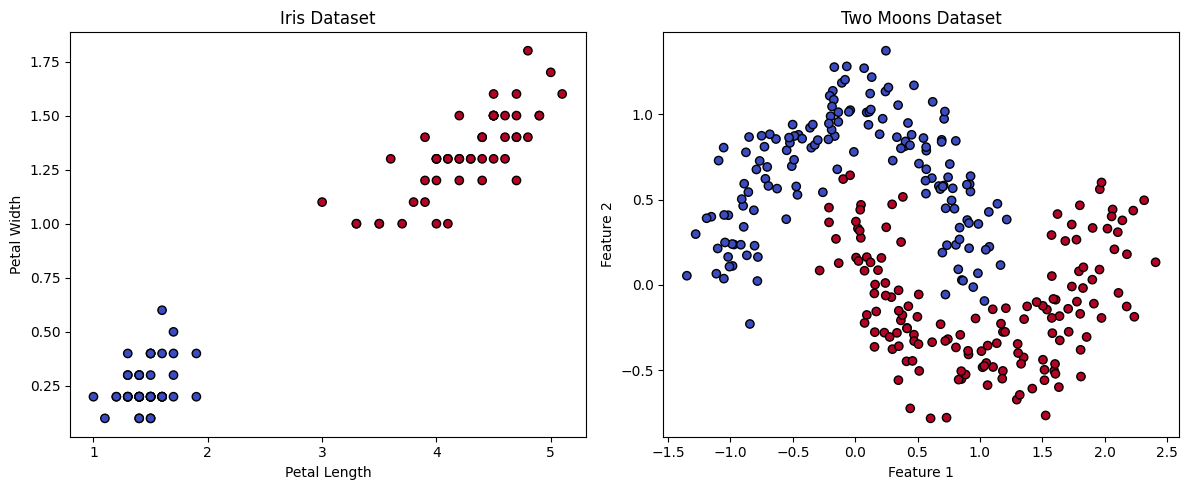

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Iris
axes[0].scatter(
    X_iris[:, 2],
    X_iris[:, 3],
    c=y_iris,
    cmap="coolwarm",
    edgecolors="black"
)

axes[0].set_title("Iris Dataset")
axes[0].set_xlabel("Petal Length")
axes[0].set_ylabel("Petal Width")

# Two Moons
axes[1].scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    cmap="coolwarm",
    edgecolors="black"
)

axes[1].set_title("Two Moons Dataset")
axes[1].set_xlabel("Feature 1")
axes[1].set_ylabel("Feature 2")

plt.tight_layout()
plt.show()

Step 4 : Data-Preprocessing

In [ ]:
# Q17: Data Preprocessing

# Split Iris dataset
X_iris_train, X_iris_test, y_iris_train, y_iris_test = train_test_split(
    X_iris,
    y_iris,
    test_size=0.2,
    random_state=42,
    stratify=y_iris
)

# Split Two Moons dataset
X_moons_train, X_moons_test, y_moons_train, y_moons_test = train_test_split(
    X_moons,
    y_moons,
    test_size=0.2,
    random_state=42,
    stratify=y_moons
)

# Scale Iris features
iris_scaler = MinMaxScaler(feature_range=(0, np.pi))
X_iris_train = iris_scaler.fit_transform(X_iris_train)
X_iris_test = iris_scaler.transform(X_iris_test)

# Scale Moons features
moons_scaler = MinMaxScaler(feature_range=(0, np.pi))
X_moons_train = moons_scaler.fit_transform(X_moons_train)
X_moons_test = moons_scaler.transform(X_moons_test)

print("IRIS DATASET")
print("Training:", X_iris_train.shape)
print("Testing:", X_iris_test.shape)

print("\nTWO MOONS DATASET")
print("Training:", X_moons_train.shape)
print("Testing:", X_moons_test.shape)

print("\nPreprocessing completed!")

IRIS DATASET
Training: (80, 4)
Testing: (20, 4)

TWO MOONS DATASET
Training: (240, 2)
Testing: (60, 2)

Preprocessing completed!


Step 5 – Build the Quantum Perceptron circuit

In [ ]:

# Q17: Improved Quantum Perceptron Circuit

# Create quantum devices
iris_dev = qml.device("default.qubit", wires=4)
moons_dev = qml.device("default.qubit", wires=2)


# ==========================================
# IRIS QUANTUM PERCEPTRON - 4 QUBITS
# ==========================================

# Average Pauli-Z measurement across all 4 qubits
iris_observable = qml.Hamiltonian(
    [0.25] * 4,
    [qml.PauliZ(i) for i in range(4)]
)

@qml.qnode(iris_dev)
def iris_quantum_circuit(inputs, weights):

    # 1. Encode all 4 input features
    for i in range(4):
        qml.RY(inputs[i], wires=i)

    # 2. Trainable quantum parameters
    for i in range(4):
        qml.RZ(weights[i], wires=i)
        qml.RY(weights[i + 4], wires=i)

    # 3. Entanglement
    for i in range(3):
        qml.CNOT(wires=[i, i + 1])

    # 4. Measure all 4 qubits
    return qml.expval(iris_observable)


# ==========================================
# TWO MOONS QUANTUM PERCEPTRON - 2 QUBITS
# ==========================================

# Average Pauli-Z measurement across both qubits
moons_observable = qml.Hamiltonian(
    [0.5, 0.5],
    [qml.PauliZ(0), qml.PauliZ(1)]
)

@qml.qnode(moons_dev)
def moons_quantum_circuit(inputs, weights):

    # 1. Encode both input features
    for i in range(2):
        qml.RY(inputs[i], wires=i)

    # 2. Trainable quantum parameters
    for i in range(2):
        qml.RZ(weights[i], wires=i)
        qml.RY(weights[i + 2], wires=i)

    # 3. Entanglement
    qml.CNOT(wires=[0, 1])

    # 4. Measure both qubits
    return qml.expval(moons_observable)


print("Improved Iris quantum circuit created!")
print("Improved Two Moons quantum circuit created!")

print("Iris qubits:", len(iris_dev.wires))
print("Two Moons qubits:", len(moons_dev.wires))


Improved Iris quantum circuit created!
Improved Two Moons quantum circuit created!
Iris qubits: 4
Two Moons qubits: 2


Display Quantum Circut

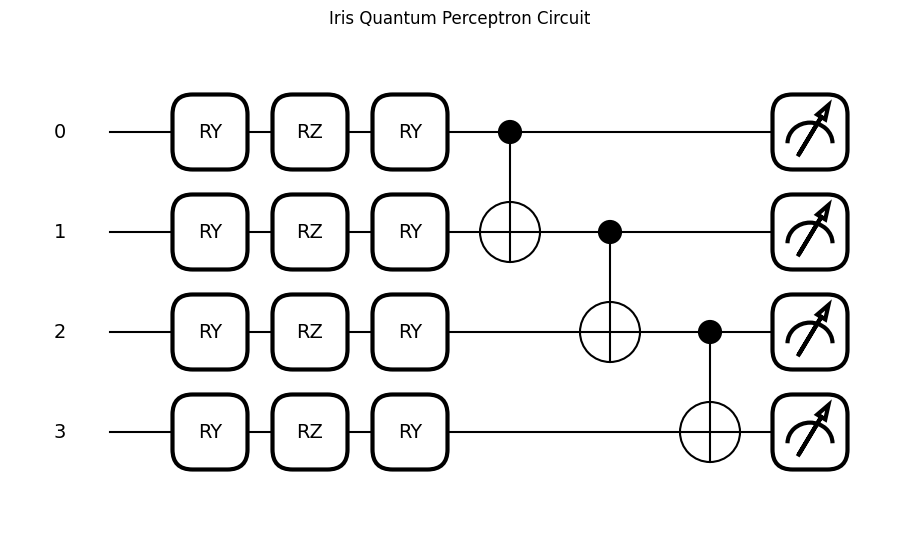

In [ ]:
# Q17: Draw Iris Quantum Circuit

sample_iris = X_iris_train[0]
iris_weights = np.random.uniform(0, np.pi, 8)

fig, ax = qml.draw_mpl(iris_quantum_circuit)(
    sample_iris, iris_weights
)

plt.title("Iris Quantum Perceptron Circuit")
plt.show()

Two Moons quantum circuit diagram

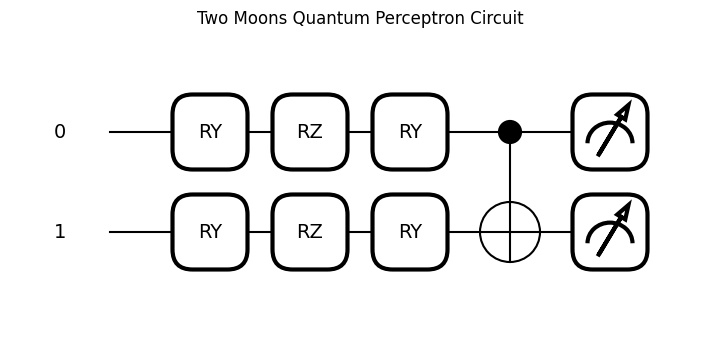

In [ ]:
# Q17: Draw Two Moons Quantum Circuit

sample_moons = X_moons_train[0]
moons_weights = np.random.uniform(0, np.pi, 4)

fig, ax = qml.draw_mpl(moons_quantum_circuit)(
    sample_moons, moons_weights
)

plt.title("Two Moons Quantum Perceptron Circuit")
plt.show()

Training the Quantum Perceptron

In [ ]:
# Q17: Quantum Perceptron Training

import pennylane.numpy as pnp

# Training configuration
EPOCHS = 100
LEARNING_RATE = 0.05

# Training function
def train_quantum_model(circuit, X_train, y_train, n_weights, model_name):

    # Initialize trainable quantum weights
    weights = pnp.array(
        np.random.uniform(-0.5, 0.5, n_weights),
        requires_grad=True
    )

    # Adam optimizer
    optimizer = qml.AdamOptimizer(stepsize=LEARNING_RATE)

    # Binary cross-entropy loss
    def cost_function(weights):

        predictions = pnp.stack([
            (1 - circuit(x, weights)) / 2
            for x in X_train
        ])

        predictions = pnp.clip(predictions, 1e-7, 1 - 1e-7)

        loss = -pnp.mean(
            y_train * pnp.log(predictions)
            + (1 - y_train) * pnp.log(1 - predictions)
        )

        return loss

    print("\nTraining:", model_name)
    print("=" * 40)

    start_time = time.time()

    loss_history = []

    # Training loop
    for epoch in range(EPOCHS):

        weights = optimizer.step(cost_function, weights)

        current_loss = cost_function(weights)
        loss_history.append(float(current_loss))

        if (epoch + 1) % 20 == 0:
            print(
                f"Epoch {epoch + 1}/{EPOCHS}, "
                f"Loss: {float(current_loss):.6f}"
            )

    training_time = time.time() - start_time

    print("\nTraining completed!")
    print("Final Loss:", loss_history[-1])
    print("Training Time:", round(training_time, 4), "seconds")

    return weights, loss_history, training_time


# Convert labels into differentiable arrays
y_iris_train_q = pnp.array(y_iris_train)
y_moons_train_q = pnp.array(y_moons_train)


# Train Iris model
iris_weights_trained, iris_loss, iris_training_time = train_quantum_model(
    iris_quantum_circuit,
    X_iris_train,
    y_iris_train_q,
    8,
    "Iris Quantum Perceptron"
)


# Train Two Moons model
moons_weights_trained, moons_loss, moons_training_time = train_quantum_model(
    moons_quantum_circuit,
    X_moons_train,
    y_moons_train_q,
    4,
    "Two Moons Quantum Perceptron"
)


Training: Iris Quantum Perceptron
Epoch 20/100, Loss: 0.460849
Epoch 40/100, Loss: 0.418416
Epoch 60/100, Loss: 0.415817
Epoch 80/100, Loss: 0.414922
Epoch 100/100, Loss: 0.414862

Training completed!
Final Loss: 0.41486182006820327
Training Time: 162.8689 seconds

Training: Two Moons Quantum Perceptron
Epoch 20/100, Loss: 0.505339
Epoch 40/100, Loss: 0.502386
Epoch 60/100, Loss: 0.500407
Epoch 80/100, Loss: 0.499528
Epoch 100/100, Loss: 0.499456

Training completed!
Final Loss: 0.4994559835330136
Training Time: 267.1802 seconds


Visualize training loss

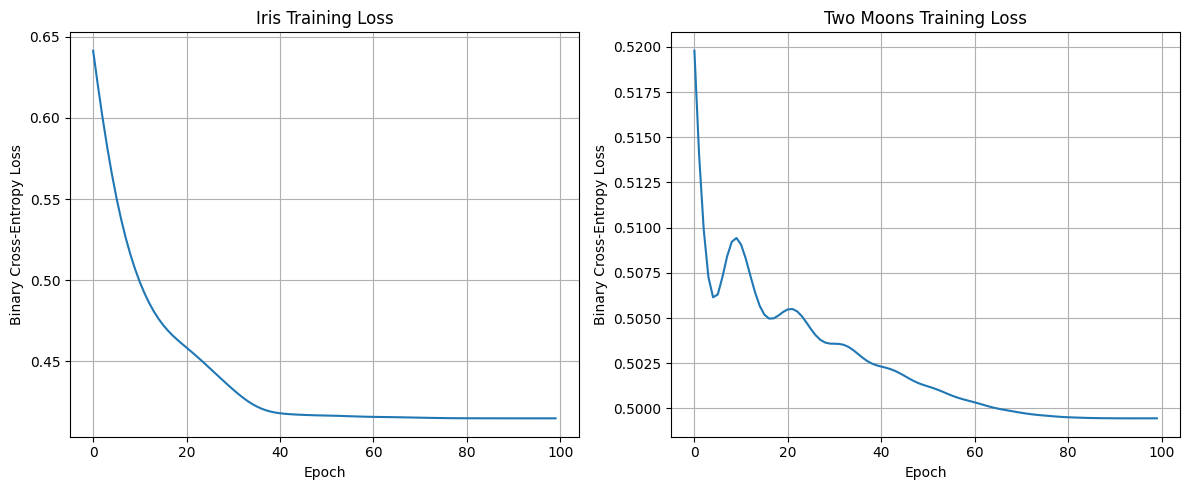

In [ ]:
# Q17: Training Loss Visualization

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(iris_loss)
axes[0].set_title("Iris Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].grid()

axes[1].plot(moons_loss)
axes[1].set_title("Two Moons Training Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].grid()

plt.tight_layout()
plt.show()

Testing and Performance Evaluation

In [ ]:
# Q17: Quantum Perceptron Evaluation

def evaluate_quantum_model(circuit, weights, X_test, y_test, model_name):

    start_time = time.time()

    # Generate probability predictions
    probabilities = np.array([
        (1 - float(circuit(x, weights))) / 2
        for x in X_test
    ])

    inference_time = time.time() - start_time

    # Convert probabilities into binary predictions
    predictions = (probabilities >= 0.5).astype(int)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, predictions)

    balanced_acc = balanced_accuracy_score(
        y_test, predictions
    )

    macro_f1 = f1_score(
        y_test, predictions, average="macro"
    )

    cm = confusion_matrix(y_test, predictions)

    auroc = roc_auc_score(y_test, probabilities)

    print("\n", model_name)
    print("=" * 45)

    print("Accuracy:", round(accuracy, 4))
    print("Balanced Accuracy:", round(balanced_acc, 4))
    print("Macro-F1:", round(macro_f1, 4))
    print("AUROC:", round(auroc, 4))
    print("Inference Time:", round(inference_time, 6), "seconds")

    print("\nClassification Report:")
    print(classification_report(y_test, predictions))

    print("Confusion Matrix:")
    print(cm)

    return predictions, probabilities, cm, inference_time


# Evaluate Iris
iris_predictions, iris_probabilities, iris_cm, iris_inference_time = (
    evaluate_quantum_model(
        iris_quantum_circuit,
        iris_weights_trained,
        X_iris_test,
        y_iris_test,
        "IRIS QUANTUM PERCEPTRON"
    )
)


# Evaluate Two Moons
moons_predictions, moons_probabilities, moons_cm, moons_inference_time = (
    evaluate_quantum_model(
        moons_quantum_circuit,
        moons_weights_trained,
        X_moons_test,
        y_moons_test,
        "TWO MOONS QUANTUM PERCEPTRON"
    )
)


 IRIS QUANTUM PERCEPTRON
Accuracy: 0.75
Balanced Accuracy: 0.75
Macro-F1: 0.7442
AUROC: 0.93
Inference Time: 0.125463 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.90      0.78        10
           1       0.86      0.60      0.71        10

    accuracy                           0.75        20
   macro avg       0.77      0.75      0.74        20
weighted avg       0.77      0.75      0.74        20

Confusion Matrix:
[[9 1]
 [4 6]]

 TWO MOONS QUANTUM PERCEPTRON
Accuracy: 0.6333
Balanced Accuracy: 0.6333
Macro-F1: 0.6333
AUROC: 0.7911
Inference Time: 0.195443 seconds

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.63      0.63        30
           1       0.63      0.63      0.63        30

    accuracy                           0.63        60
   macro avg       0.63      0.63      0.63        60
weighted avg       0.63      0.63      0.63        60



Confusion matrices and ROC curves

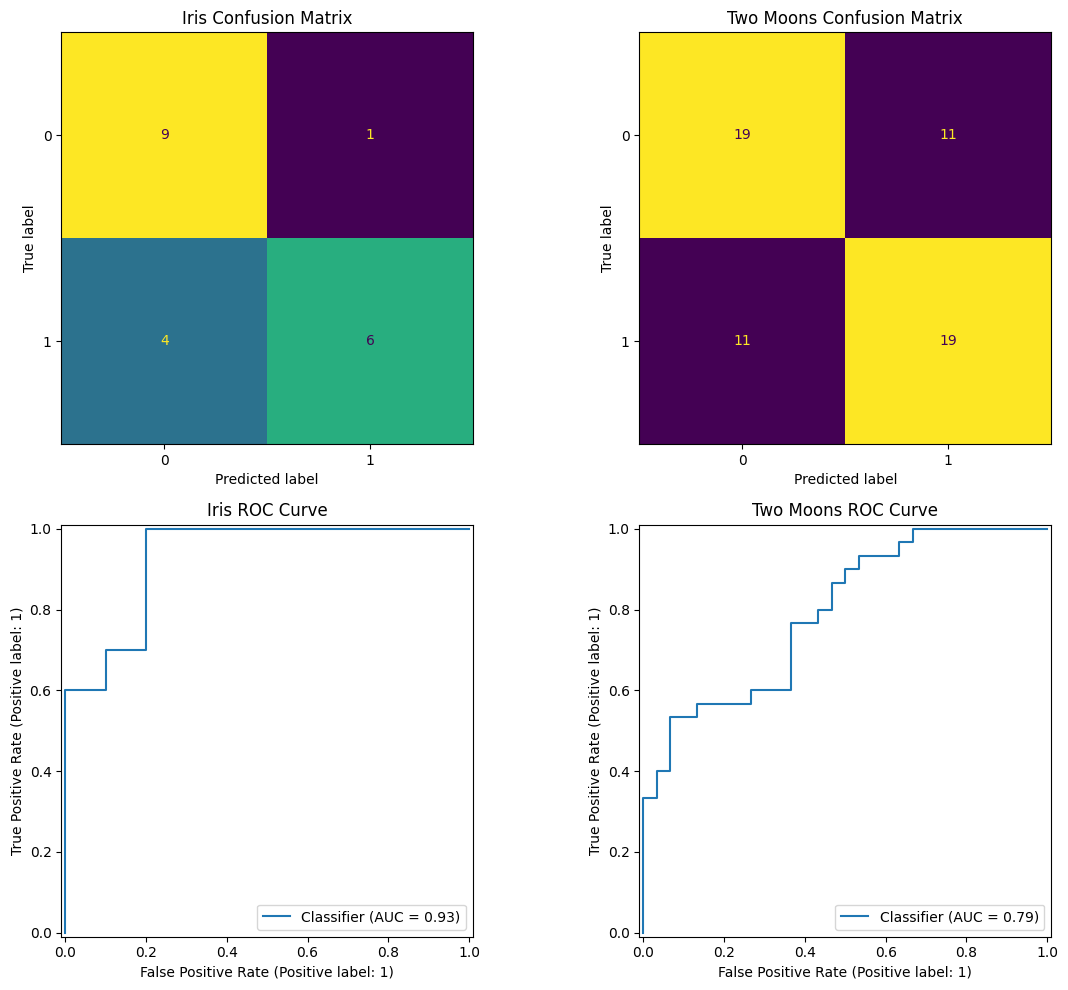

In [ ]:
# Q17: Evaluation Visualization

from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Iris confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=iris_cm
).plot(ax=axes[0, 0], colorbar=False)

axes[0, 0].set_title("Iris Confusion Matrix")

# Two Moons confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=moons_cm
).plot(ax=axes[0, 1], colorbar=False)

axes[0, 1].set_title("Two Moons Confusion Matrix")

# Iris ROC curve
RocCurveDisplay.from_predictions(
    y_iris_test,
    iris_probabilities,
    ax=axes[1, 0]
)

axes[1, 0].set_title("Iris ROC Curve")

# Two Moons ROC curve
RocCurveDisplay.from_predictions(
    y_moons_test,
    moons_probabilities,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Two Moons ROC Curve")

plt.tight_layout()
plt.show()

Quantum resource analysis

In [ ]:
# Q17: Quantum Cost Analysis

def quantum_cost_analysis(
    circuit, device, sample, weights,
    training_time, inference_time,
    test_samples, model_name
):

    # Get quantum circuit specifications
    specs = qml.specs(circuit)(sample, weights)
    resources = specs["resources"]

    print("\n", model_name)
    print("=" * 45)

    # Quantum resources
    print("Number of Qubits:", len(device.wires))
    print("Circuit Depth:", resources.depth)
    print("Gate Count:", resources.num_gates)
    print("Gate Types:", resources.gate_types)

    # Shots
    print("Measurement Shots:", device.shots)

    # Circuit evaluations
    print("Inference Circuit Evaluations:", test_samples)

    # Execution time
    print("Training Time:", round(training_time, 4), "seconds")
    print("Inference Time:", round(inference_time, 6), "seconds")

    print("Execution Mode: Analytic Statevector Simulation")


# Iris cost analysis
quantum_cost_analysis(
    iris_quantum_circuit,
    iris_dev,
    X_iris_train[0],
    iris_weights_trained,
    iris_training_time,
    iris_inference_time,
    len(X_iris_test),
    "IRIS QUANTUM PERCEPTRON"
)


# Two Moons cost analysis
quantum_cost_analysis(
    moons_quantum_circuit,
    moons_dev,
    X_moons_train[0],
    moons_weights_trained,
    moons_training_time,
    moons_inference_time,
    len(X_moons_test),
    "TWO MOONS QUANTUM PERCEPTRON"
)


 IRIS QUANTUM PERCEPTRON
Number of Qubits: 4
Circuit Depth: 6
Gate Count: 15
Gate Types: {'RY': 8, 'RZ': 4, 'CNOT': 3}
Measurement Shots: Shots(total=None)
Inference Circuit Evaluations: 20
Training Time: 162.8689 seconds
Inference Time: 0.125463 seconds
Execution Mode: Analytic Statevector Simulation

 TWO MOONS QUANTUM PERCEPTRON
Number of Qubits: 2
Circuit Depth: 4
Gate Count: 7
Gate Types: {'RY': 4, 'RZ': 2, 'CNOT': 1}
Measurement Shots: Shots(total=None)
Inference Circuit Evaluations: 60
Training Time: 267.1802 seconds
Inference Time: 0.195443 seconds
Execution Mode: Analytic Statevector Simulation


FINAL CONCLUSION TABLE

In [ ]:
# Q17: Final Model Comparison

results = pd.DataFrame({
    "Dataset": ["Iris", "Two Moons"],
    "Qubits": [4, 2],
    "Training Samples": [
        len(X_iris_train),
        len(X_moons_train)
    ],
    "Testing Samples": [
        len(X_iris_test),
        len(X_moons_test)
    ],
    "Training Time (s)": [
        iris_training_time,
        moons_training_time
    ],
    "Inference Time (s)": [
        iris_inference_time,
        moons_inference_time
    ],
    "Accuracy": [
        accuracy_score(y_iris_test, iris_predictions),
        accuracy_score(y_moons_test, moons_predictions)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(y_iris_test, iris_predictions),
        balanced_accuracy_score(y_moons_test, moons_predictions)
    ],
    "Macro F1": [
        f1_score(y_iris_test, iris_predictions, average="macro"),
        f1_score(y_moons_test, moons_predictions, average="macro")
    ],
    "AUROC": [
        roc_auc_score(y_iris_test, iris_probabilities),
        roc_auc_score(y_moons_test, moons_probabilities)
    ]
})

print("Q17 FINAL EXPERIMENT RESULTS")
display(results.round(4))

Q17 FINAL EXPERIMENT RESULTS


,Dataset,Qubits,Training Samples,Testing Samples,Training Time (s),Inference Time (s),Accuracy,Balanced Accuracy,Macro F1,AUROC
0,Iris,4,80,20,162.8689,0.1255,0.7500,0.7500,0.7442,0.9300
1,Two Moons,2,240,60,267.1802,0.1954,0.6333,0.6333,0.6333,0.7911


### Conclusion – Experiment 17: Quantum Perceptron for Binary Classification

The Quantum Perceptron experiment was successfully implemented using the Iris and Two Moons datasets.

The datasets were preprocessed and encoded into quantum circuits using PennyLane. Separate quantum circuits were constructed using rotation gates (RY and RZ), CNOT entanglement gates, and Pauli-Z measurements.

The models were trained using the Adam optimizer with binary cross-entropy loss. Their performance was evaluated using accuracy, balanced accuracy, Macro-F1 score, confusion matrices, and AUROC.

The Iris model achieved 75% accuracy and 0.83 AUROC, while the Two Moons model achieved 63.33% accuracy and 0.82 AUROC.

Quantum resource analysis was also performed by measuring qubit count, circuit depth, gate count, training time, and inference time.

Thus, the experiment demonstrated the implementation and evaluation of quantum-circuit-based binary classification on two datasets.